In [1]:
import numpy as np
import matplotlib.pyplot as plt

import pywt

# Add files up one level to the path
import sys
sys.path.append("../..")

import scipy.sparse as sps
from scipy.fft import dct, idct
import jlinops

import sys
import os

from wavelets import WaveletTransformOperator2D

import jlinops

import matplotlib.gridspec as gridspec

from msolver import IASGKS, MMGKS, VanillaGKS

# Setup toy problem

In [2]:
image = jlinops.cameraman()
img_shape = image.shape
x_true = image.flatten()

noise_sigma = 0.05
A = jlinops.Gaussian2DBlurOperator(img_shape, blur_sigma=2.0, mode="wrap")
#A = WaveletTransformOperator2D(img_shape, wavelet="haar", level=3)
b_true = A @ x_true
b = b_true + noise_sigma*np.random.normal(size=A.shape[0])
naive_recon = A.T @ b
noise_var = noise_sigma**2

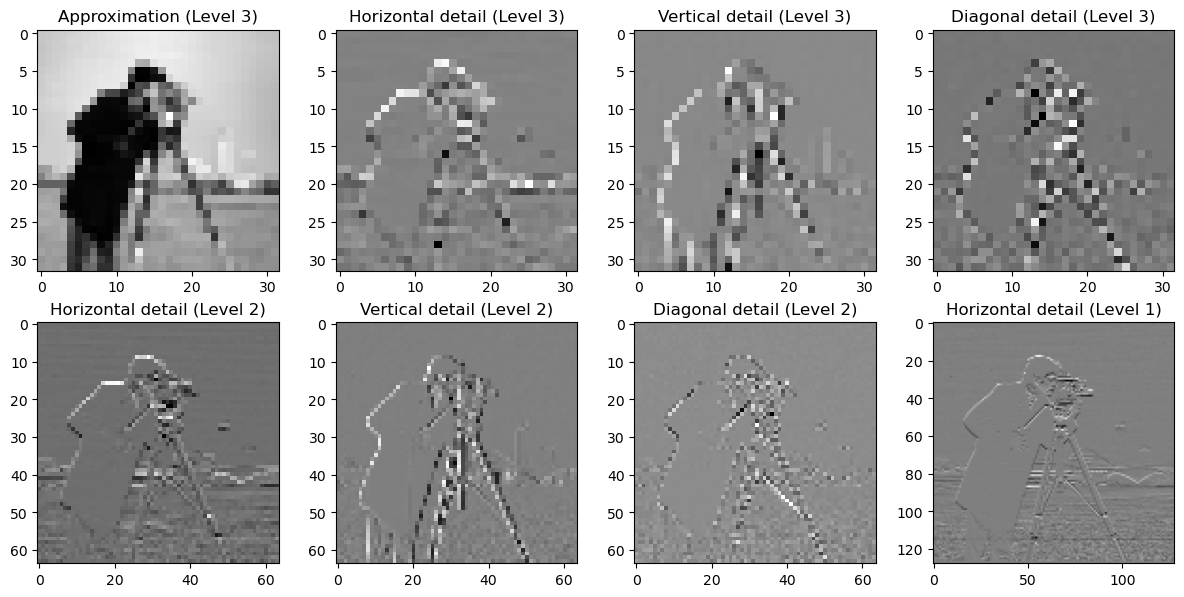

In [3]:
# Create a sample 2D image (e.g., 256x256 random matrix)

# Perform 2D wavelet decomposition using Haar wavelet, with 3 levels
coeffs = pywt.wavedec2(image, 'haar', level=3)

# coeffs is a list containing the approximation coefficients and detail coefficients
# The first element of coeffs is the approximation coefficient at level 3
# The subsequent elements are tuples of detail coefficients (horizontal, vertical, diagonal) for each level

# Extract the approximation coefficients at the final level (level 3)
cA3 = coeffs[0]

# Extract the detail coefficients (cH, cV, cD) for each level
(cH3, cV3, cD3), (cH2, cV2, cD2), (cH1, cV1, cD1) = coeffs[1:]

# Plotting the approximation and detail coefficients for visualization
fig, ax = plt.subplots(2, 4, figsize=(12, 6))

# Level 3 coefficients
ax[0, 0].imshow(cA3, cmap='gray')
ax[0, 0].set_title('Approximation (Level 3)')

ax[0, 1].imshow(cH3, cmap='gray')
ax[0, 1].set_title('Horizontal detail (Level 3)')

ax[0, 2].imshow(cV3, cmap='gray')
ax[0, 2].set_title('Vertical detail (Level 3)')

ax[0, 3].imshow(cD3, cmap='gray')
ax[0, 3].set_title('Diagonal detail (Level 3)')

# Level 2 coefficients
ax[1, 0].imshow(cH2, cmap='gray')
ax[1, 0].set_title('Horizontal detail (Level 2)')

ax[1, 1].imshow(cV2, cmap='gray')
ax[1, 1].set_title('Vertical detail (Level 2)')

ax[1, 2].imshow(cD2, cmap='gray')
ax[1, 2].set_title('Diagonal detail (Level 2)')

# Level 1 coefficients
ax[1, 3].imshow(cH1, cmap='gray')
ax[1, 3].set_title('Horizontal detail (Level 1)')

# Adjust layout and show the plot
plt.tight_layout()
plt.show()


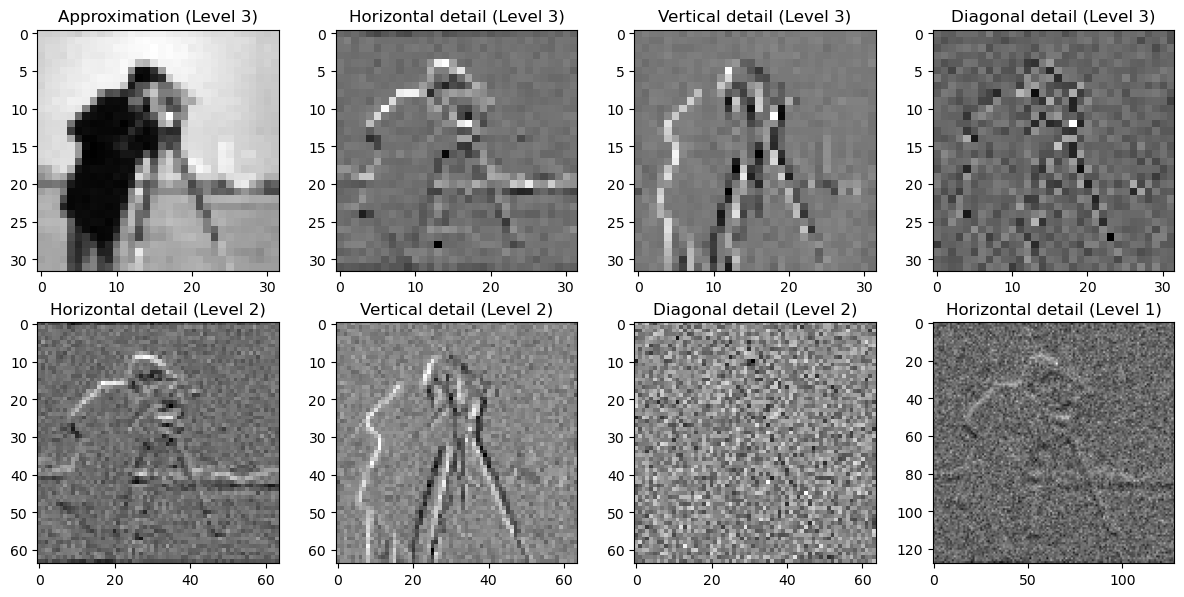

In [4]:
# Create a sample 2D image (e.g., 256x256 random matrix)

# Perform 2D wavelet decomposition using Haar wavelet, with 3 levels
coeffs = pywt.wavedec2(b.reshape(img_shape), 'haar', level=3)

# coeffs is a list containing the approximation coefficients and detail coefficients
# The first element of coeffs is the approximation coefficient at level 3
# The subsequent elements are tuples of detail coefficients (horizontal, vertical, diagonal) for each level

# Extract the approximation coefficients at the final level (level 3)
cA3 = coeffs[0]

# Extract the detail coefficients (cH, cV, cD) for each level
(cH3, cV3, cD3), (cH2, cV2, cD2), (cH1, cV1, cD1) = coeffs[1:]

# Plotting the approximation and detail coefficients for visualization
fig, ax = plt.subplots(2, 4, figsize=(12, 6))

# Level 3 coefficients
ax[0, 0].imshow(cA3, cmap='gray')
ax[0, 0].set_title('Approximation (Level 3)')

ax[0, 1].imshow(cH3, cmap='gray')
ax[0, 1].set_title('Horizontal detail (Level 3)')

ax[0, 2].imshow(cV3, cmap='gray')
ax[0, 2].set_title('Vertical detail (Level 3)')

ax[0, 3].imshow(cD3, cmap='gray')
ax[0, 3].set_title('Diagonal detail (Level 3)')

# Level 2 coefficients
ax[1, 0].imshow(cH2, cmap='gray')
ax[1, 0].set_title('Horizontal detail (Level 2)')

ax[1, 1].imshow(cV2, cmap='gray')
ax[1, 1].set_title('Vertical detail (Level 2)')

ax[1, 2].imshow(cD2, cmap='gray')
ax[1, 2].set_title('Diagonal detail (Level 2)')

# Level 1 coefficients
ax[1, 3].imshow(cH1, cmap='gray')
ax[1, 3].set_title('Horizontal detail (Level 1)')

# Adjust layout and show the plot
plt.tight_layout()
plt.show()


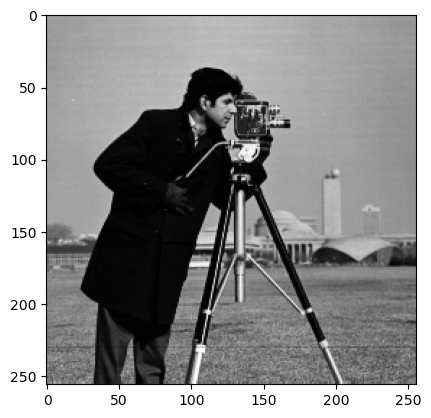

In [5]:
plt.imshow(image, cmap="gray")
plt.show()

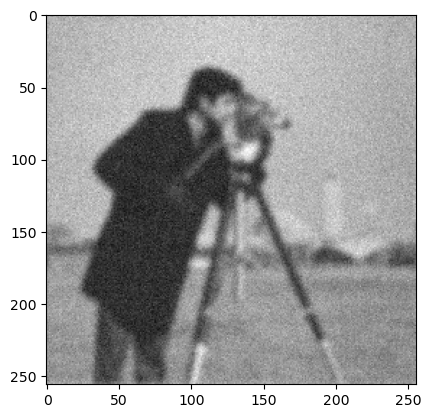

In [6]:
plt.imshow(b.reshape(img_shape), cmap="gray")
plt.show()

# Set up prior

In [7]:
# This can be figured out later
# mask = np.zeros(Lpre.shape[0])
# mask[ Lpre.detail_indices ] = 1
# P = jlinops.Subsampling1DOperator(mask)
#L = P @ Lpre

L = WaveletTransformOperator2D(img_shape, wavelet="haar", level=3)
K = None
Lpinv_factory = lambda wr: L.T @ jlinops.MatrixLinearOperator(sps.diags(1.0/wr))

In [8]:
# Set method
method = "dp"

# Weight params
q = 1.0
epsilon = 1e-4
weight_params = {
    "q": q,
    "epsilon": epsilon,
}

# Build solver
mmgks_solver = MMGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)
gks_solver = VanillaGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

xker = None
ground_truth = x_true.copy()

In [9]:
vdata = gks_solver.solve(n_iter=50, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, weight_params={},
                                    regparam_kwargs={"eta":1.01},  xker=xker)

pdata = mmgks_solver.solve_with_priorconditioning(n_iter=50, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                                 regparam=method, x_true=ground_truth, weight_params=weight_params, 
                                                 regparam_kwargs={"eta":1.01})


data = mmgks_solver.solve(n_iter=50, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, weight_params=weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker)

11.054871681240641
11.543131107186245
11.840304649405315
12.012657681838412
12.106225582748047
12.158999978044541
12.188343829340367
12.204649764427929
12.21369089229031
12.218646302343084
12.221251364526875
12.222683840442217
12.223409494417362
12.22380072361984
12.224006032054309
12.224114788457413
12.22417204539156
12.224202127433603
12.22421793872204
12.22422610435987
12.224230473216046
12.224232691831354
12.224233828124694
12.224234431122694
12.224234729525516
12.224234887882774
12.22423497077898
12.224235014073805
12.224235035739493
12.22423504624032
12.224235051964518
12.224235054863884
12.224235056323156
12.224235057101092
12.224235057479655
12.224235057683247
12.224235057784885
12.224235057836573
12.224235057863488
12.224235057877287
12.224235057884643
12.224235057888109
12.224235057889736
12.224235057890702
12.22423505789106
12.224235057891317
12.224235057891503
12.224235057891507
12.224235057891546
12.224235057891578
Augmented basis with initial guess!


1e-07


/Users/jonathanlindbloom/Github/IRLS_prec_GSBL/tests/2d_blur_wavelets/../../msolver.py:712: UserWarning: Inequality is NOT satisfied, no solution to the DP problem...
  warnings.warn("Inequality is NOT satisfied, no solution to the DP problem...", UserWarning)


1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
2.9787459177003446
5.476388083846586
6.6355645700111
7.456687017737497
8.11976948427946
8.62611294293595
8.992716702163923
9.289657122728348
9.526076881014754
9.753253864954893
9.969964919321157
10.124505226934758
10.239622840254022
10.336807779619795
10.421265397359091
10.496234940466348
10.562124747224422
10.614758267855253
10.657667807510819
10.693142891590274
10.726986854792697
10.756989007569835
10.777198691031822
10.795624032831288
10.815821446655912
10.834639545992946
10.843899171702308
10.847871726976233
10.849895332014656
10.852508077570468
10.850823605068275
10.846128818915776
10.839772410329658
Augmented basis with initial guess!


18.905717399318714
13.211143873528224
12.765970237449558
10.77197774502914
11.068697751201954
10.12543403027015
10.317435943732292
9.993426790127359
9.950118415108912
9.865998471412373
9.780521163179028
9.725464776285964
9.582285071582106
9.574145191474534
9.525928635573852
9.434798841516265
9.37582733804507
9.342051580728258
9.29375944552947
9.267603060122209
9.222291210258083
9.182254124706795
9.148333811294263
9.125070915104303
9.113183731224293
9.098455323888201
9.080701728808188
9.080712739358711
9.079479863136328
9.063736283556683
9.057942163956533
9.057713742640255
9.065129122695488
9.053532454393507
9.058565744225957
9.069071356849593
9.08134919168925
9.093126942630347
9.10495024581464
9.101276606878887
9.088761426004782
9.070232086434242
9.055758616959114
9.0521805933252
9.043154560893127
9.04849691433045
9.06275739955288
9.053977755541268
9.064061388014144
9.073418787238513


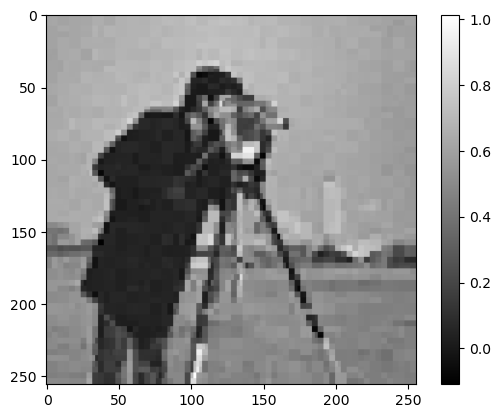

In [10]:
plt.imshow(pdata["x"].reshape(img_shape), cmap="gray")
plt.colorbar()
plt.show()

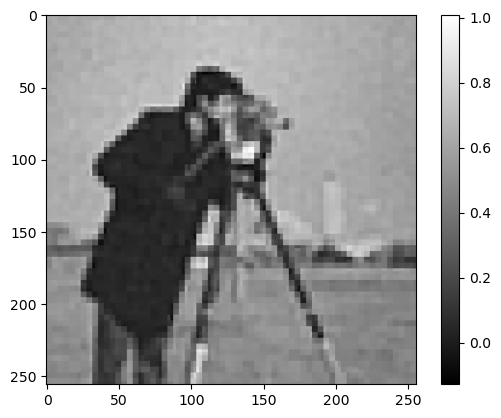

In [11]:
plt.imshow(data["x"].reshape(img_shape), cmap="gray")
plt.colorbar()
plt.show()

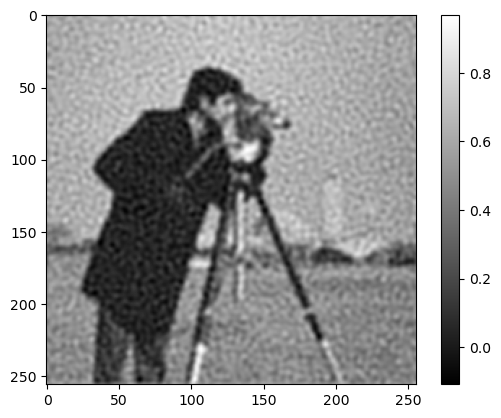

In [12]:
plt.imshow(vdata["x"].reshape(img_shape), cmap="gray")
plt.colorbar()
plt.show()

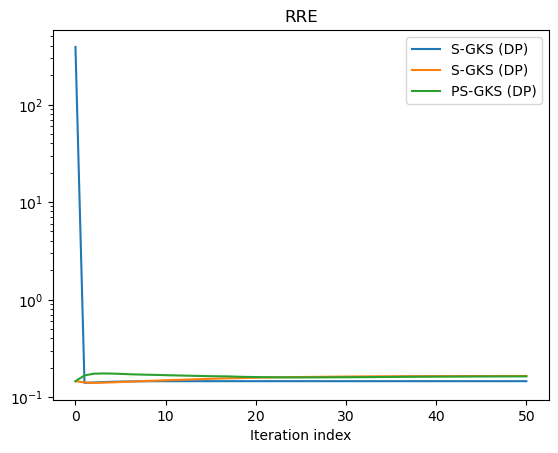

In [13]:
plt.semilogy(vdata["rre_history"], label="S-GKS (DP)")
plt.semilogy(data["rre_history"], label="S-GKS (DP)")
# plt.semilogy(data_opt["rre_history"], label="S-GKS (optimal)", ls="--", alpha=0.7)
plt.semilogy(pdata["rre_history"], label="PS-GKS (DP)")
# plt.semilogy(pdata_opt["rre_history"], label="PS-GKS (optimal)", ls="--", alpha=0.7)
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
plt.title("RRE")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

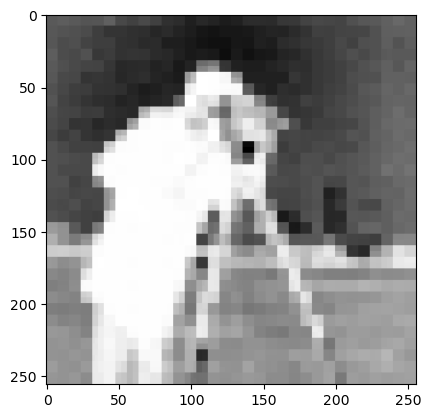

In [14]:
plt.imshow( (pdata["Lopinv"] @ pdata["V"][:,0]).reshape(img_shape) , cmap="gray")
plt.show()

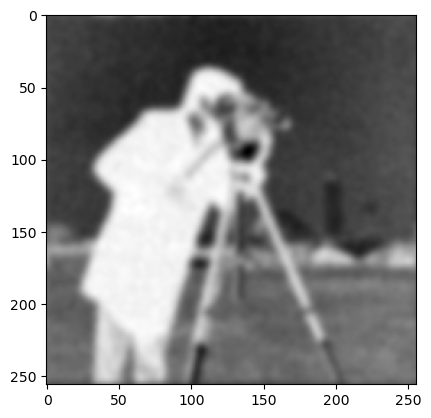

In [15]:
plt.imshow( (data["V"][:,0]).reshape(img_shape) , cmap="gray")
plt.show()